<p align="center"><img src="img/qelux_logo.jpg" alt="Qelux" width="260"></p>

# 🐾 Qelux · Pipeline de Machine Learning para estrategia de clientes
**Caso práctico evaluable — Tema 16: Machine Learning (EBIS)**  
Autor: Claudio Abreu Afonso

> **Modelamos cómo compran los clientes, no qué compran.**  
> **Usamos un e-commerce de referencia como proxy.**

**Índice**
- F0. Planteamiento de negocio y dataset
- F1. Carga y EDA inicial
- F2. Limpieza
- F3. Ingeniería de variables por cliente (RFM) y target
- F4. No supervisado: segmentación de clientes
- F5. Supervisado: predicción de riesgo de fuga
- F6. Evaluación final e interpretación
- F7. Conclusiones y recomendaciones para Qelux

## ▶️ Cómo ejecutar este notebook
1. **Dataset:** descargar *Online Retail* del UCI Machine Learning Repository → https://archive.ics.uci.edu/dataset/352/online+retail (botón *Download*), descomprimir y colocar `Online Retail.xlsx` **en la misma carpeta que este notebook**. La primera ejecución crea `online_retail.csv` para que las siguientes cargas sean rápidas.
2. **Imágenes:** la carpeta `img/` (incluida en el repositorio) debe estar junto al notebook para ver el logo y las fotos.
3. **Librerías:** `pip install pandas numpy matplotlib seaborn scikit-learn openpyxl`
4. **Ejecutar:** *Run All* de principio a fin (≈ 1–2 minutos). Resultados reproducibles con `RANDOM_STATE = 42`; las versiones usadas se muestran en la última celda.

---
# F0. Planteamiento de negocio y dataset

## 0.1 Contexto de negocio
> 🐾 **Qelux es una marca real.** Fue un emprendimiento propio del autor de este trabajo: una marca española de productos premium para mascotas que vendió a través de Amazon FBA y que actualmente está en pausa. El autor tiene intención de **retomarla**, y este caso práctico construye la base analítica para ese **relanzamiento con una estrategia de clientes basada en datos**.

Qelux es una marca española de productos premium para mascotas, fundada por un emprendedor venezolano, que operó vendiendo a través de Amazon FBA. Su principal limitación es que Amazon es el propietario de la relación con el cliente: Qelux no conoce quién le compra, con qué frecuencia ni quién deja de hacerlo, lo que le impide diseñar estrategias de fidelización.

Como parte de su plan de relanzamiento (e-commerce propio y posterior entrada en tiendas físicas como marca de **alta gama para mascotas**), Qelux quiere construir **desde el día uno una estrategia de clientes basada en datos**. Al no disponer todavía de histórico propio, nuestro equipo desarrolla y valida el pipeline sobre un **e-commerce de referencia** (UCI Online Retail, Reino Unido, 2010-2011), modelando únicamente variables de comportamiento de compra, trasladables a cualquier sector. Cuando Qelux acumule sus propios datos, el pipeline se reentrenará con ellos.

**Producto estrella: el comedero antivoracidad.** No es un consumible: es el **producto de entrada**. El modelo de recompra le dice a Qelux **qué clientes convertir en clientes de catálogo** cuando lance más productos (venta cruzada, segunda mascota, recambios del inserto).

<p align="center"><img src="img/qelux_comedero_yorkshire.jpg" alt="Comedero Qelux en uso" height="260">&nbsp;<img src="img/qelux_comedero_despiece.jpg" alt="Despiece: inserto antivoracidad, cuenco de acero y base de silicona" height="260"></p>
<p align="center"><em>Comedero antivoracidad Qelux: inserto antivoracidad tipo llanta, cuenco de acero inoxidable y base de silicona con ventosas.</em></p>


## 0.2 Preguntas que resuelve el proyecto
1. **No supervisado:** ¿qué tipos de clientes existen según su comportamiento de compra? → segmentación RFM con clustering.
2. **Supervisado:** ¿qué clientes **no** volverán a comprar en los próximos 3 meses? → clasificación binaria de riesgo de fuga (*churn*).

## 0.3 Justificación del dataset
- **Relevancia:** reproduce la tabla de pedidos que genera cualquier e-commerce (Zooplus, Tiendanimal o una tienda Shopify como la que lanzará Qelux), por lo que el pipeline es directamente trasladable.
- **Complejidad:** 541.909 transacciones (8 columnas) de 4.372 clientes en 38 países entre dic-2010 y dic-2011, con problemas reales de calidad: **24,93 % de registros sin `CustomerID`** (135.080 filas), 1.454 productos sin descripción, **9.288 líneas de facturas canceladas**, cantidades y precios negativos (mínimos de −80.995 unidades y −11.062 £) y valores extremos (máximos de 80.995 unidades y 38.970 £ por unidad). Además, exige transformar el dato de nivel **transacción** a nivel **cliente** antes de modelar.
- **Adecuación:** modelamos comportamiento de compra, no producto. Además mezcla clientes mayoristas y particulares, la misma dualidad que tendrá Qelux (web propia + tiendas físicas).

## 0.4 Coste de los errores y métrica principal
Clase positiva: **y = 1 → el cliente NO vuelve a comprar** (riesgo de fuga).

| Error | Qué pasa | Coste |
|---|---|---|
| **Falso negativo** (se iba a ir y no lo detectamos) | No recibe incentivo → se pierde el cliente | **Alto** (todo su valor futuro) |
| **Falso positivo** (lo marcamos en riesgo y habría vuelto) | Recibe un incentivo innecesario | Bajo |

➡️ **Métrica principal: recall de la clase 1**, vigilando la precisión (coste de incentivos).

**Incentivos coherentes con una marca premium** (no descuentos del 15%, que abaratan la marca): envío gratis · inserto antivoracidad de regalo · puntos de fidelidad · acceso anticipado a lanzamientos.

## 0.5 Limitación asumida
Los patrones concretos (umbrales, tamaño de segmentos) pertenecen al comercio de referencia y deberán recalibrarse con los datos de Qelux. **Se transfiere la metodología, no los números.**

---
# F1. Carga y EDA inicial

In [122]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [123]:
# Carga: la primera vez desde Excel (lento), después desde CSV (rápido)
import os

XLSX = 'Online Retail.xlsx'
CSV  = 'online_retail.csv'

if os.path.exists(CSV):
    df_raw = pd.read_csv(CSV, parse_dates=['InvoiceDate'], dtype={'InvoiceNo': str, 'StockCode': str})
else:
    df_raw = pd.read_excel(XLSX, dtype={'InvoiceNo': str, 'StockCode': str})
    df_raw.to_csv(CSV, index=False)

df = df_raw.copy()
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [124]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [125]:
# Nulos por columna (absoluto y %)
nulos = pd.DataFrame({'nulos': df.isna().sum(), '%': (df.isna().mean()*100).round(2)})
nulos

,nulos,%
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [126]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [127]:
print('Rango de fechas:', df['InvoiceDate'].min(), '→', df['InvoiceDate'].max())
print('Facturas canceladas (empiezan por C):', df['InvoiceNo'].str.startswith('C').sum())
print('Clientes únicos:', df['CustomerID'].nunique())
print('Países:', df['Country'].nunique())

Rango de fechas: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Facturas canceladas (empiezan por C): 9288
Clientes únicos: 4372
Países: 38


In [128]:
# Peso de cada país (top 5) en % de líneas
(df['Country'].value_counts(normalize=True).head(5)*100).round(2)

Country
United Kingdom    91.43
Germany            1.75
France             1.58
EIRE               1.51
Spain              0.47
Name: proportion, dtype: float64

### 📝 Diagnóstico F1
- **Tamaño:** 541.909 filas × 8 columnas, de 4.372 clientes en 38 países (dic-2010 → dic-2011).
- **CustomerID nulo en el 24,93 % de las filas (135.080):** sin cliente no podemos saber cuántas veces compró ni si volvió, así que esas filas no sirven para segmentar ni para predecir recompra. **Decisión:** se eliminan en F2 y se documenta. 
⚠️ Probablemente son compras como invitado, que podrían comportarse distinto (posible sesgo).

- **Valores anómalos en `describe()`:**
  - Quantity va de −80.995 a +80.995: es un pedido y su **cancelación**. Las facturas que empiezan por "C" (9.288 líneas) anulan pedidos con cantidades negativas.
  - UnitPrice tiene mínimo −11.062 £: es un **ajuste contable** de la tienda, no una compra.
  - Ambos casos inflan los extremos y se tratarán en F2.
- **Concentración geográfica:** Reino Unido acumula el 91,43 % de las líneas (España solo el 0,47 %). El cliente "medio" del proxy es británico: se transfiere la metodología, no los números.

---
# F2. Limpieza
> Cada decisión de limpieza: **qué** se elimina, **cuántas filas** y **por qué**.
> Las decisiones salen directamente del Diagnóstico F1.

Registramos el número de filas tras cada paso en un *log* para poder justificarlo en el informe.

In [129]:
# Copia de trabajo + registro de cada paso de limpieza
df_clean = df.copy()
log_limpieza = [('0. Dataset original', len(df_clean))]

def registrar(paso):
    log_limpieza.append((paso, len(df_clean)))
    print(f'{paso}: {len(df_clean):,} filas')

## 2.1 Filas sin `CustomerID`
Sin cliente no podemos calcular su frecuencia ni saber si vuelve → no sirven para segmentar ni predecir.

In [130]:
df_clean = df_clean.dropna(subset=['CustomerID'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
registrar('1. Sin CustomerID eliminados')

1. Sin CustomerID eliminados: 406,829 filas


## 2.2 Cancelaciones (facturas que empiezan por "C")
No las tiramos sin más: las **guardamos aparte** (`df_cancel`) porque el nº de devoluciones de un cliente puede ser una variable útil en F3. Después:
1. Quitamos las líneas "C" del dataset de compras.
2. Quitamos también las **compras que fueron anuladas** por esas cancelaciones (mismo cliente, mismo producto y misma cantidad). Si no, pedidos erróneos como el de 80.995 unidades seguirían contando como compras reales.

> Emparejamiento **uno a uno**: cada cancelación anula **una sola** compra (la más reciente) del mismo cliente, producto y cantidad. Así no borramos compras repetidas legítimas.

In [131]:
es_cancel = df_clean['InvoiceNo'].str.startswith('C')
df_cancel = df_clean[es_cancel].copy()
print(f'Líneas de cancelación: {len(df_cancel):,}')

df_clean = df_clean[~es_cancel]
registrar('2a. Líneas de cancelación (C) separadas')

# Compras anuladas: cada cancelación anula UNA compra (la más reciente) con mismo cliente + producto + cantidad
claves = ['CustomerID', 'StockCode', 'Quantity']
n_cancel = (df_cancel.assign(Quantity=-df_cancel['Quantity'])
                     .groupby(claves).size().rename('n_cancel'))

df_clean = df_clean.sort_values('InvoiceDate')
orden_desc = df_clean.groupby(claves).cumcount(ascending=False)   # 0 = compra más reciente
n_para_fila = df_clean[claves].merge(n_cancel, left_on=claves, right_index=True, how='left')['n_cancel'].fillna(0).values
anulada = orden_desc.values < n_para_fila

print('Compras anuladas detectadas:', anulada.sum())
print(df_clean[anulada].nlargest(3, 'Quantity')[['InvoiceNo','Description','Quantity','CustomerID']])

df_clean = df_clean[~anulada]
registrar('2b. Compras anuladas por una cancelación')

Líneas de cancelación: 8,905
2a. Líneas de cancelación (C) separadas: 397,924 filas
Compras anuladas detectadas: 3188
       InvoiceNo                         Description  Quantity  CustomerID
540421    581483         PAPER CRAFT , LITTLE BIRDIE     80995       16446
61619     541431      MEDIUM CERAMIC TOP STORAGE JAR     74215       12346
160546    550461  FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       15749
2b. Compras anuladas por una cancelación: 394,736 filas


## 2.3 Cantidades o precios ≤ 0
Una compra real tiene cantidad y precio positivos. Lo que queda con ≤ 0 son ajustes o regalos sin valor.

In [132]:
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
registrar('3. Cantidad o precio <= 0')

3. Cantidad o precio <= 0: 394,699 filas


## 2.4 Códigos que no son productos
Los productos tienen un `StockCode` que empieza por **5 dígitos** (ej. `85123A`). El resto son portes (`POST`), comisiones (`BANK CHARGES`), ajustes manuales (`M`), etc. No son comportamiento de compra.

In [133]:
es_producto = df_clean['StockCode'].str.match(r'^\d{5}')
print('Códigos eliminados (top 10):')
print(df_clean.loc[~es_producto, 'StockCode'].value_counts().head(10))

df_clean = df_clean[es_producto]
registrar('4. Códigos no producto')

Códigos eliminados (top 10):
StockCode
POST            1070
M                230
C2               132
DOT               16
BANK CHARGES      12
PADS               3
Name: count, dtype: int64
4. Códigos no producto: 393,236 filas


## 2.5 Duplicados exactos

In [134]:
df_clean = df_clean.drop_duplicates()
registrar('5. Duplicados exactos')

5. Duplicados exactos: 388,098 filas


## 2.6 Variable de importe y resumen de la limpieza

In [135]:
df_clean['Importe'] = df_clean['Quantity'] * df_clean['UnitPrice']

resumen = pd.DataFrame(log_limpieza, columns=['Paso', 'Filas'])
resumen['Eliminadas'] = (-resumen['Filas'].diff()).fillna(0).astype(int)
resumen['% del original'] = (resumen['Filas'] / resumen['Filas'].iloc[0] * 100).round(2)
display(resumen)

print(f"Clientes tras limpieza: {df_clean['CustomerID'].nunique():,}")
print(f"Rango de fechas: {df_clean['InvoiceDate'].min()} → {df_clean['InvoiceDate'].max()}")
df_clean[['Quantity','UnitPrice','Importe']].describe().round(2)

,Paso,Filas,Eliminadas,% del original
0,0. Dataset original,541909,0,100.00
1,1. Sin CustomerID eliminados,406829,135080,75.07
2,2a. Líneas de cancelación (C) separadas,397924,8905,73.43
3,2b. Compras anuladas por una cancelación,394736,3188,72.84
4,3. Cantidad o precio <= 0,394699,37,72.83
5,4. Códigos no producto,393236,1463,72.56
6,5. Duplicados exactos,388098,5138,71.62


Clientes tras limpieza: 4,322
Rango de fechas: 2010-12-01 08:26:00 → 2011-12-09 12:50:00


,Quantity,UnitPrice,Importe
count,388098.00,388098.00,388098.00
mean,12.66,2.85,21.40
std,42.12,3.98,68.53
min,1.00,0.04,0.06
25%,2.00,1.25,4.95
50%,6.00,1.95,11.90
75%,12.00,3.75,19.80
max,4800.00,649.50,7144.72


## 2.7 Valores extremos: ¿los quitamos?
Miramos los pedidos más grandes que quedan **después** de limpiar.

In [136]:
df_clean.nlargest(5, 'Importe')[['InvoiceNo','Description','Quantity','UnitPrice','Importe','CustomerID','Country']]

,InvoiceNo,Description,Quantity,UnitPrice,Importe,CustomerID,Country
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749,United Kingdom
421601,573003,RABBIT NIGHT LIGHT,2400,2.08,4992.00,14646,Netherlands
52709,540815,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,4921.50,15749,United Kingdom
52772,540818,DOORMAT FAIRY CAKE,670,6.75,4522.50,15749,United Kingdom


In [137]:
print("Quedan despues de limpiar:", df_clean.shape [0], "filas y", df_clean.shape [1], "columnas")

Quedan despues de limpiar: 388098 filas y 9 columnas


## 2.8 Concentración del gasto 
¿Qué % del gasto total genera el 1 % de clientes que más gasta?

In [138]:
# Concentración del gasto: ¿qué % del gasto total genera el 1 % de clientes que más gasta?
gasto_cliente = df_clean.groupby('CustomerID')['Importe'].sum().sort_values(ascending=False)
top_1 = int(len(gasto_cliente) * 0.01)
pct = gasto_cliente.head(top_1).sum() / gasto_cliente.sum() * 100
print(f'El top 1 % de clientes ({top_1} clientes) genera el {pct:.1f} % del gasto total')

El top 1 % de clientes (43 clientes) genera el 30.0 % del gasto total


### 📝 Decisiones F2
- **Resultado:** de 541.909 filas pasamos a **388.098 filas y 4.322 clientes** (conservamos el **71,62 %**). El dataset queda con 9 columnas (las 8 originales + `Importe`).
- **Paso más costoso:** eliminar las filas sin `CustomerID` (−135.080, el 24,93 %). Es razonable: sin cliente no hay análisis de clientes. El resto de pasos elimina poco (≈ 3,5 % en total) y corrige ruido real: cancelaciones, compras anuladas (incluido el pedido erróneo de 80.995 unidades), códigos no producto y duplicados.
- **Valores extremos:** los pedidos más grandes que quedan (540–3.114 unidades, precios normales de 1,45–8,15 £) corresponden a **clientes mayoristas reales**, no a errores. **No se eliminan**: Qelux también tendrá clientes B2B (tiendas físicas) y el modelo debe aprender a reconocerlos. La asimetría que generan se tratará en F4 con transformación logarítmica.
- **Hallazgo:** el 1 % de los clientes concentra el 30 % del gasto (patrón de Pareto), lo que anticipa segmentos muy diferenciados en F4.

---
# F3. Ingeniería de variables por cliente (RFM) y target
Pasamos de **una fila por línea de factura** a **una fila por cliente**.

> ⚠️ **Fuga temporal (data leakage):** las variables se calculan **solo con datos anteriores a la fecha de corte**; el target, **solo con los 90 días posteriores**. Así simulamos la situación real de Qelux: *"con lo que sé hoy, ¿qué clientes no volverán en los próximos 3 meses?"*

```
──────────── PASADO ────────────┃──── FUTURO (90 días) ────
 dic-2010 → 08-sep-2011          ┃  09-sep-2011 → 07-dic-2011
 → variables del cliente (X)     ┃  → ¿vuelve a comprar? (y)
                         FECHA DE CORTE
```

In [139]:
FECHA_CORTE  = pd.Timestamp('2011-09-09')
VENTANA_DIAS = 90   # horizonte para definir si el cliente vuelve
FIN_VENTANA  = FECHA_CORTE + pd.Timedelta(days=VENTANA_DIAS)

pasado = df_clean[df_clean['InvoiceDate'] <  FECHA_CORTE]
futuro = df_clean[(df_clean['InvoiceDate'] >= FECHA_CORTE) & (df_clean['InvoiceDate'] < FIN_VENTANA)]

print(f'Pasado : {pasado["InvoiceDate"].min().date()} → {pasado["InvoiceDate"].max().date()} | {len(pasado):,} líneas | {pasado["CustomerID"].nunique():,} clientes')
print(f'Futuro : {futuro["InvoiceDate"].min().date()} → {futuro["InvoiceDate"].max().date()} | {len(futuro):,} líneas | {futuro["CustomerID"].nunique():,} clientes')

Pasado : 2010-12-01 → 2011-09-08 | 229,798 líneas | 3,355 clientes
Futuro : 2011-09-09 → 2011-12-07 | 155,226 líneas | 2,862 clientes


## 3.1 Variables de comportamiento por cliente (solo pasado)

| Variable | Qué mide |
|---|---|
| **Recencia** | Días desde la última compra hasta la fecha de corte (R) |
| **Frecuencia** | Nº de pedidos distintos (F) |
| **Monetario** | Gasto total en £ (M) |
| **Ticket_medio** | Gasto medio por pedido |
| **Antiguedad** | Días desde la primera compra hasta la fecha de corte |
| **Dias_entre_compras** | Tiempo medio entre pedidos (si solo hay 1 pedido = antigüedad) |
| **Productos_distintos** | Variedad de catálogo comprada |
| **Unidades_por_pedido** | Tamaño medio del pedido (mayorista vs particular) |
| **Num_cancelaciones** | Pedidos cancelados antes del corte |
| **Es_UK** | 1 si el cliente es de Reino Unido |

In [140]:
clientes = pasado.groupby('CustomerID').agg(
    ultima_compra       = ('InvoiceDate', 'max'),
    primera_compra      = ('InvoiceDate', 'min'),
    Frecuencia          = ('InvoiceNo',   'nunique'),
    Monetario           = ('Importe',     'sum'),
    Productos_distintos = ('StockCode',   'nunique'),
    Unidades            = ('Quantity',    'sum'),
    Pais                = ('Country',     lambda s: s.mode()[0]),
)

clientes['Recencia']            = (FECHA_CORTE - clientes['ultima_compra']).dt.days
clientes['Antiguedad']          = (FECHA_CORTE - clientes['primera_compra']).dt.days
clientes['Ticket_medio']        = clientes['Monetario'] / clientes['Frecuencia']
clientes['Unidades_por_pedido'] = clientes['Unidades'] / clientes['Frecuencia']
dias_activo = (clientes['ultima_compra'] - clientes['primera_compra']).dt.days
clientes['Dias_entre_compras']  = np.where(clientes['Frecuencia'] > 1,
                                           dias_activo / (clientes['Frecuencia'] - 1),
                                           clientes['Antiguedad'])
clientes['Es_UK'] = (clientes['Pais'] == 'United Kingdom').astype(int)

# Cancelaciones del cliente ANTES del corte (df_cancel viene de F2)
cancel_pasado = df_cancel[df_cancel['InvoiceDate'] < FECHA_CORTE]
clientes['Num_cancelaciones'] = cancel_pasado.groupby('CustomerID')['InvoiceNo'].nunique()
clientes['Num_cancelaciones'] = clientes['Num_cancelaciones'].fillna(0).astype(int)

clientes = clientes.drop(columns=['ultima_compra', 'primera_compra', 'Unidades', 'Pais'])
print('Clientes con historial antes del corte:', len(clientes))
clientes.head()

Clientes con historial antes del corte: 3355


,Frecuencia,Monetario,Productos_distintos,Recencia,Antiguedad,Ticket_medio,Unidades_por_pedido,Dias_entre_compras,Es_UK,Num_cancelaciones
CustomerID,,,,,,,,,,
12347,5,2790.86,82,37,275,558.172000,318.000000,59.25,0,0
12348,3,1167.24,21,156,266,389.080000,705.333333,54.50,0,0
12350,1,294.40,16,218,218,294.400000,196.000000,218.00,0,0
12352,3,521.18,24,175,204,173.726667,62.000000,14.50,0,3
12353,1,89.00,4,112,112,89.000000,20.000000,112.00,0,0


## 3.2 Target: ¿el cliente NO vuelve en los próximos 90 días?
`Fuga = 1` → no compra nada en la ventana futura (riesgo de fuga, la clase que nos interesa detectar).
`Fuga = 0` → vuelve a comprar.

Fuga
Vuelve (0)    1900
Fuga (1)      1455
Name: count, dtype: int64
Fuga
Vuelve %    56.63
Fuga %      43.37
Name: proportion, dtype: float64


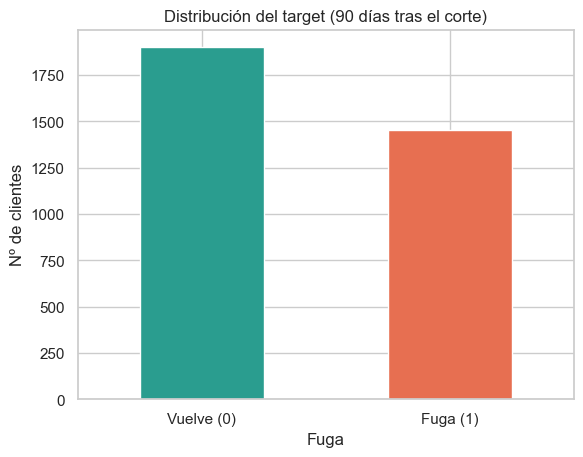

In [141]:
vuelven = set(futuro['CustomerID'].unique())
clientes['Fuga'] = (~clientes.index.isin(vuelven)).astype(int)

reparto = clientes['Fuga'].value_counts().rename({0: 'Vuelve (0)', 1: 'Fuga (1)'})
print(reparto)
print((clientes['Fuga'].value_counts(normalize=True) * 100).round(2).rename({0: 'Vuelve %', 1: 'Fuga %'}))

ax = reparto.plot(kind='bar', color=['#2a9d8f', '#e76f51'], rot=0)
ax.set_title('Distribución del target (90 días tras el corte)')
ax.set_ylabel('Nº de clientes')
plt.show()

## 3.3 Comprobación anti-fuga y resumen del dataset de modelado

In [142]:
# Ninguna variable puede usar información posterior al corte
assert pasado['InvoiceDate'].max() < FECHA_CORTE
assert cancel_pasado['InvoiceDate'].max() < FECHA_CORTE
print('✅ Sin fuga temporal: todas las variables usan datos anteriores a', FECHA_CORTE.date())

print('Dataset de modelado:', clientes.shape[0], 'clientes y', clientes.shape[1] - 1, 'variables + target')
clientes.describe().round(1)

✅ Sin fuga temporal: todas las variables usan datos anteriores a 2011-09-09
Dataset de modelado: 3355 clientes y 10 variables + target


,Frecuencia,Monetario,Productos_distintos,Recencia,Antiguedad,Ticket_medio,Unidades_por_pedido,Dias_entre_compras,Es_UK,Num_cancelaciones,Fuga
count,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0,3355.0
mean,3.5,1530.5,49.5,94.2,181.2,366.0,220.2,93.7,0.9,0.7,0.4
std,5.7,5827.8,67.1,79.8,80.1,450.8,303.4,75.6,0.3,1.8,0.5
min,1.0,2.9,1.0,0.0,0.0,2.9,1.0,0.0,0.0,0.0,0.0
25%,1.0,256.4,14.0,25.0,121.0,166.1,83.4,35.0,1.0,0.0,0.0
50%,2.0,545.7,29.0,74.0,192.0,275.8,148.0,68.0,1.0,0.0,0.0
75%,4.0,1340.0,62.0,150.0,263.0,408.7,257.0,141.5,1.0,1.0,1.0
max,130.0,177333.6,1219.0,281.0,281.0,9341.3,5104.5,281.0,1.0,31.0,1.0


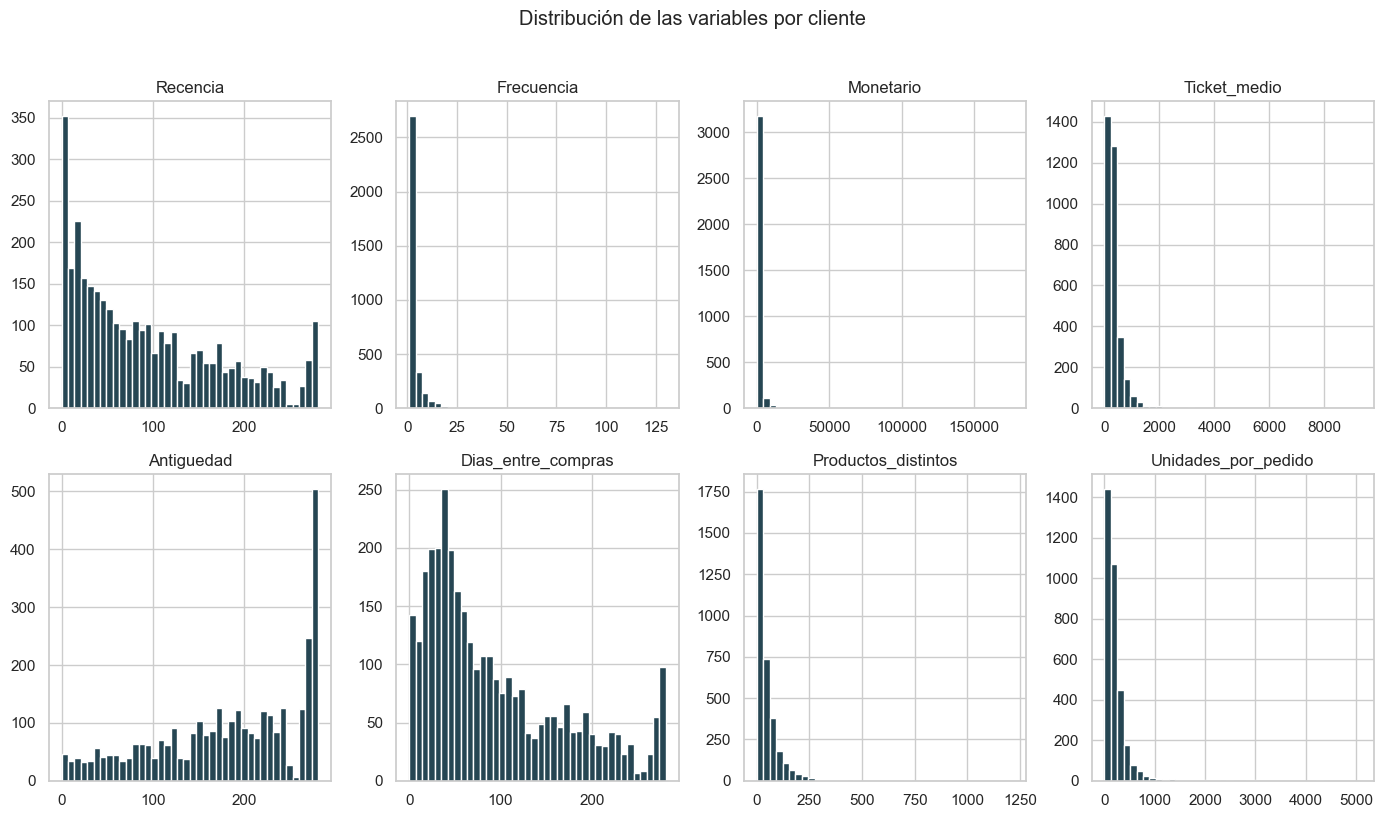

Asimetría (skew):
Monetario              17.5
Frecuencia              9.2
Ticket_medio            8.7
Unidades_por_pedido     7.2
Productos_distintos     6.2
Dias_entre_compras      0.9
Recencia                0.8
Antiguedad             -0.5
dtype: float64


In [143]:
# Asimetría: ¿cómo se distribuyen las variables? (anticipa la transformación log de F4)
vars_num = ['Recencia','Frecuencia','Monetario','Ticket_medio','Antiguedad',
            'Dias_entre_compras','Productos_distintos','Unidades_por_pedido']
clientes[vars_num].hist(bins=40, figsize=(14, 8), layout=(2, 4), color='#264653')
plt.suptitle('Distribución de las variables por cliente', y=1.02)
plt.tight_layout()
plt.show()
print('Asimetría (skew):')
print(clientes[vars_num].skew().round(1).sort_values(ascending=False))

In [144]:
# ¿Se diferencian los que se fugan de los que vuelven? (medianas por grupo)
clientes.groupby('Fuga')[vars_num + ['Num_cancelaciones', 'Es_UK']].median().round(1).T.rename(columns={0: 'Vuelve', 1: 'Fuga'})

Fuga,Vuelve,Fuga
Recencia,48.0,113.0
Frecuencia,3.0,1.0
Monetario,848.6,339.6
Ticket_medio,299.4,239.4
Antiguedad,205.0,174.0
Dias_entre_compras,52.7,100.0
Productos_distintos,42.0,19.0
Unidades_por_pedido,171.2,128.0
Num_cancelaciones,0.0,0.0
Es_UK,1.0,1.0


### 📝 Decisiones F3
- **Dataset de modelado:** 3.355 clientes con historial antes del corte, 10 variables + target. **43 % se fuga** y 57 % vuelve: desbalanceo **leve** (no como un 90/10). En F5 usaremos split estratificado (`stratify`) y priorizaremos el **recall de la clase Fuga**.
- **Fecha de corte (9-sep-2011) y fuga temporal:** las variables se calculan solo con compras **anteriores** al corte y el target solo con los **90 días posteriores**. Si mezclásemos ambos periodos, el modelo "vería el futuro" (p. ej., usaría compras de octubre para predecir si el cliente vuelve en octubre) y daría resultados irreales. En Qelux sería como decidir hoy a quién enviar un incentivo usando ventas que aún no han ocurrido.
- **Variables que más separan (medianas Vuelve vs Fuga):**
  - **Recencia:** 48 vs 113 días (×2,4). Quien lleva más tiempo sin comprar es quien menos vuelve: el indicador clásico de fuga.
  - **Frecuencia:** 3 vs 1 pedido (×3). Muchos de los que se fugan solo compraron una vez.
  - **Monetario:** 849 £ vs 340 £ (×2,5) y **Productos distintos:** 42 vs 19 (×2,2). Los clientes fieles gastan más y exploran más catálogo, justo lo que Qelux busca con el comedero como producto de entrada.
- **Asimetría (skew):** Monetario (17,5), Frecuencia (9,2), Ticket medio (8,7), Unidades por pedido (7,2) y Productos distintos (6,2) tienen colas muy largas a la derecha: muchos clientes pequeños y unos pocos mayoristas enormes. **Problema para K-Means:** trabaja con distancias y medias, así que esos pocos gigantes arrastrarían los centroides y el clustering separaría "gigantes vs resto" en lugar de perfiles útiles. **Solución en F4:** transformación logarítmica (`log1p`) + escalado (`StandardScaler`). Antigüedad (−0,5) es casi simétrica y no preocupa.

---
# F4. No supervisado: segmentación de clientes
**Pregunta de negocio:** ¿qué tipos de clientes existen según cómo compran?

**Pipeline:** variables de comportamiento → `log1p` (corrige la asimetría vista en F3) → `StandardScaler` (misma escala, K-Means usa distancias) → K-Means (elegir K con codo + silueta) → comparación con GMM y DBSCAN → PCA 2D para visualizar → perfiles de negocio.

> El target `Fuga` **no** se usa para segmentar (esto es aprendizaje no supervisado). Solo lo miramos **después**, para ver si los segmentos tienen relación con la fuga.

In [145]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

vars_seg = ['Recencia', 'Frecuencia', 'Monetario', 'Ticket_medio', 'Productos_distintos', 'Unidades_por_pedido']

X_seg_log = np.log1p(clientes[vars_seg])                 # 1) corrige asimetría
scaler_seg = StandardScaler()
X_seg = scaler_seg.fit_transform(X_seg_log)               # 2) misma escala

print('Skew antes del log :', clientes[vars_seg].skew().round(1).to_dict())
print('Skew después del log:', X_seg_log.skew().round(1).to_dict())

Skew antes del log : {'Recencia': 0.8, 'Frecuencia': 9.2, 'Monetario': 17.5, 'Ticket_medio': 8.7, 'Productos_distintos': 6.2, 'Unidades_por_pedido': 7.2}
Skew después del log: {'Recencia': -1.0, 'Frecuencia': 1.4, 'Monetario': 0.4, 'Ticket_medio': -0.0, 'Productos_distintos': -0.2, 'Unidades_por_pedido': -0.4}


## 4.1 ¿Cuántos segmentos? Codo (inercia) + coeficiente de silueta
- **Inercia:** siempre baja al subir K → buscamos el *codo*.
- **Silueta** (−1 a 1): cuánto se parece cada cliente a su grupo frente al grupo vecino. Más alto = grupos más separados.

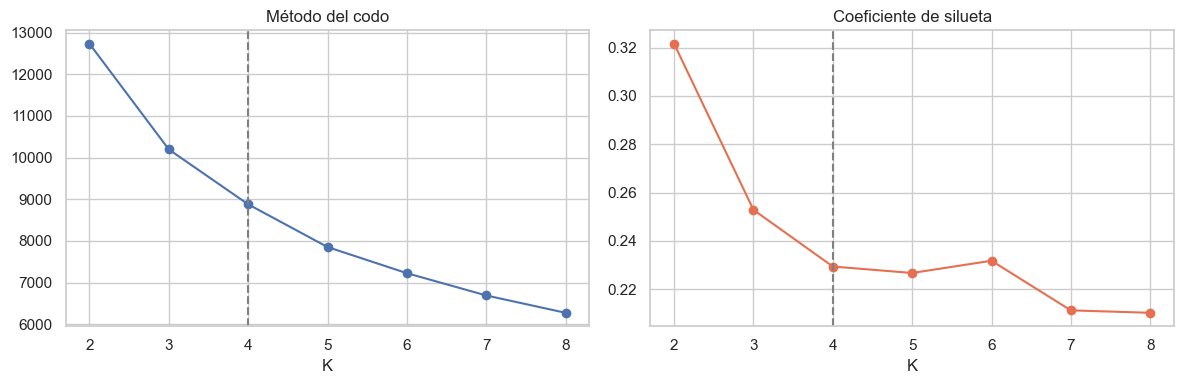

,Inercia,Silueta
K,,
2,12730.194,0.322
3,10194.620,0.253
4,8877.312,0.229
5,7852.701,0.227
6,7225.468,0.232
7,6690.648,0.211
8,6274.633,0.210


In [146]:
resultados_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
    resultados_k.append((k, km.inertia_, silhouette_score(X_seg, km.labels_)))
resultados_k = pd.DataFrame(resultados_k, columns=['K', 'Inercia', 'Silueta']).set_index('K')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
resultados_k['Inercia'].plot(marker='o', ax=ax[0], title='Método del codo')
resultados_k['Silueta'].plot(marker='o', ax=ax[1], color='#e76f51', title='Coeficiente de silueta')
for a in ax: a.axvline(4, ls='--', color='grey'); a.set_xlabel('K')
plt.tight_layout(); plt.show()
resultados_k.round(3)

**Elección: K = 4.** K = 2 tiene la silueta más alta, pero solo separaría "buenos vs malos" clientes (poco accionable). A partir de K = 4 la inercia baja cada vez menos (codo) y la silueta se estabiliza. Con 4 segmentos obtenemos perfiles **interpretables y accionables** para marketing: el criterio final es de negocio, como vimos en clase.

In [147]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
clientes['Segmento_id'] = kmeans.labels_

# Perfil de cada segmento en unidades reales (medianas) + tamaño + % de fuga
perfil = clientes.groupby('Segmento_id')[vars_seg].median().round(1)
perfil['Nº clientes'] = clientes['Segmento_id'].value_counts()
perfil['% del total'] = (perfil['Nº clientes'] / len(clientes) * 100).round(1)
perfil['% Fuga']      = (clientes.groupby('Segmento_id')['Fuga'].mean() * 100).round(1)
perfil

,Recencia,Frecuencia,Monetario,Ticket_medio,Productos_distintos,Unidades_por_pedido,Nº clientes,% del total,% Fuga
Segmento_id,,,,,,,,,
0,14.0,7.0,2077.1,318.8,82.0,183.9,725,21.6,13.4
1,102.0,1.0,380.5,253.3,23.0,137.0,1363,40.6,52.2
2,133.0,1.0,136.9,113.8,8.0,48.0,638,19.0,65.2
3,65.0,2.0,1327.2,597.1,53.0,371.5,629,18.7,36.7


## 4.2 Nombre de negocio para cada segmento
⚠️ El número del cluster (0, 1, 2, 3) es **arbitrario** y puede cambiar entre ejecuciones. Por eso asignamos los nombres con **reglas sobre el perfil**, no a mano por número:
- **VIP fieles:** el de mayor gasto y menor recencia.
- **Dormidos de bajo valor:** el de menor gasto.
- **Mayoristas / ticket alto:** de los restantes, el de mayor ticket medio.
- **Ocasionales:** el que queda.

In [148]:
p = perfil.copy()
nombres = {}
vip = (p['Monetario'].rank(ascending=False) + p['Recencia'].rank()).idxmin();  nombres[vip] = 'VIP fieles'
resto = p.drop(index=vip)
dorm = resto['Monetario'].idxmin();                                            nombres[dorm] = 'Dormidos de bajo valor'
resto = resto.drop(index=dorm)
may = resto['Ticket_medio'].idxmax();                                          nombres[may] = 'Mayoristas / ticket alto'
nombres[resto.drop(index=may).index[0]] = 'Ocasionales'

clientes['Segmento'] = clientes['Segmento_id'].map(nombres)
perfil.index = perfil.index.map(nombres)
orden = ['VIP fieles', 'Mayoristas / ticket alto', 'Ocasionales', 'Dormidos de bajo valor']
perfil = perfil.loc[orden]
perfil

,Recencia,Frecuencia,Monetario,Ticket_medio,Productos_distintos,Unidades_por_pedido,Nº clientes,% del total,% Fuga
Segmento_id,,,,,,,,,
VIP fieles,14.0,7.0,2077.1,318.8,82.0,183.9,725,21.6,13.4
Mayoristas / ticket alto,65.0,2.0,1327.2,597.1,53.0,371.5,629,18.7,36.7
Ocasionales,102.0,1.0,380.5,253.3,23.0,137.0,1363,40.6,52.2
Dormidos de bajo valor,133.0,1.0,136.9,113.8,8.0,48.0,638,19.0,65.2


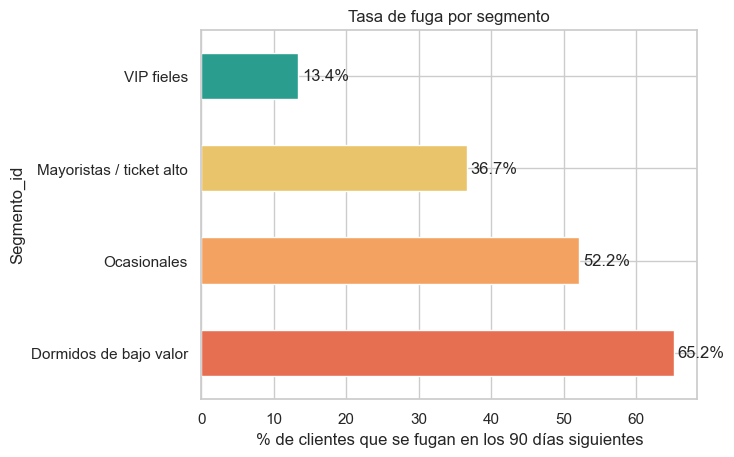

In [149]:
# ¿Los segmentos (creados SIN mirar la fuga) se relacionan con la fuga?
ax = perfil['% Fuga'].plot(kind='barh', color=['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51'])
ax.set_xlabel('% de clientes que se fugan en los 90 días siguientes')
ax.set_title('Tasa de fuga por segmento')
ax.invert_yaxis()
for i, v in enumerate(perfil['% Fuga']): ax.text(v + 0.5, i, f'{v}%', va='center')
plt.show()

## 4.3 Comparación con otros algoritmos de clustering
Probamos los otros dos métodos vistos en clase sobre los mismos datos transformados:
- **GMM** (Gaussian Mixture): clusters elípticos y asignación probabilística.
- **DBSCAN**: basado en densidad, no necesita K y marca ruido (−1).

In [150]:
# GMM con 4 componentes
gmm = GaussianMixture(n_components=K_FINAL, covariance_type='full', n_init=3, random_state=RANDOM_STATE).fit(X_seg)
labels_gmm = gmm.predict(X_seg)

# DBSCAN: eps elegido con el criterio de distancias a vecinos (percentil 90 de la distancia al 12º vecino)
from sklearn.neighbors import NearestNeighbors
dist = NearestNeighbors(n_neighbors=12).fit(X_seg).kneighbors(X_seg)[0][:, -1]
eps = np.percentile(dist, 90)
labels_db = DBSCAN(eps=eps, min_samples=12).fit_predict(X_seg)
n_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)

comparativa = pd.DataFrame({
    'Algoritmo': ['K-Means (K=4)', 'GMM (4 componentes)', f'DBSCAN (eps={eps:.2f})'],
    'Nº clusters': [K_FINAL, len(set(labels_gmm)), n_db],
    'Silueta': [silhouette_score(X_seg, kmeans.labels_),
                silhouette_score(X_seg, labels_gmm),
                silhouette_score(X_seg[labels_db != -1], labels_db[labels_db != -1]) if n_db > 1 else np.nan],
    '% ruido': [0, 0, round((labels_db == -1).mean() * 100, 1)],
})
comparativa.round(3)

,Algoritmo,Nº clusters,Silueta,% ruido
0,K-Means (K=4),4,0.229,0.0
1,GMM (4 componentes),4,0.058,0.0
2,DBSCAN (eps=1.13),1,NaN,4.3


## 4.4 Visualización con PCA (2 componentes)
Las 6 variables no se pueden dibujar; PCA las proyecta en 2D conservando la mayor varianza posible (solo para **visualizar**).

Varianza explicada por PC1 + PC2: 81.1 %


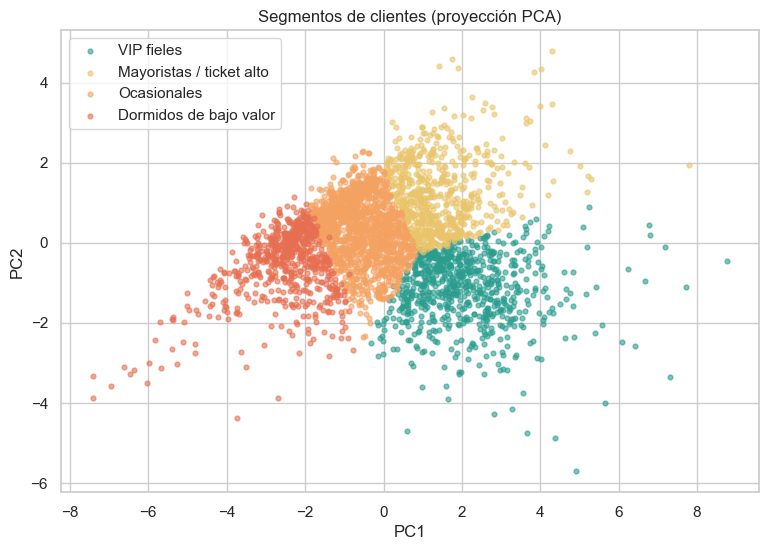

,PC1,PC2
Recencia,-0.30,0.47
Frecuencia,0.39,-0.51
Monetario,0.52,-0.03
Ticket_medio,0.40,0.51
Productos_distintos,0.43,-0.11
Unidades_por_pedido,0.39,0.50


In [151]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_seg)
print(f'Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum()*100:.1f} %')

colores = {'VIP fieles': '#2a9d8f', 'Mayoristas / ticket alto': '#e9c46a',
           'Ocasionales': '#f4a261', 'Dormidos de bajo valor': '#e76f51'}
fig, ax = plt.subplots(figsize=(9, 6))
for seg in orden:
    m = (clientes['Segmento'] == seg).values
    ax.scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.6, label=seg, color=colores[seg])
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('Segmentos de clientes (proyección PCA)')
ax.legend(); plt.show()

# ¿Qué variables pesan en cada componente?
pd.DataFrame(pca.components_.T, index=vars_seg, columns=['PC1', 'PC2']).round(2)

### 📝 Decisiones F4
- **Preparación:** `log1p` redujo la asimetría (Monetario de 17,5 a 0,4) y `StandardScaler` puso todas las variables en la misma escala. Sin ello, K-Means (basado en distancias y medias) habría separado solo "mayoristas gigantes vs resto".
- **Elección de K = 4:** K = 2 tiene más silueta pero solo separa "buenos vs malos" (poco accionable). Con K = 4 la inercia empieza a estabilizarse y los perfiles son interpretables para marketing.
- **Segmentos:**
  - **VIP fieles (21,6 %, fuga 13,4 %):** los más recurrentes, los que más gastan y más catálogo exploran. Hay que cuidarlos y darles trato preferente → **acceso anticipado** a lanzamientos.
  - **Mayoristas / ticket alto (18,7 %, fuga 36,7 %):** compran poco a menudo pero en grandes cantidades para revender. ⚠️ Parte de su "fuga" puede deberse a ciclos de reposición superiores a 90 días (limitación de la ventana) → **envío gratis** en pedidos grandes.
  - **Ocasionales (40,6 %, fuga 52,2 %):** el grupo más grande; vuelven cuando se acuerdan de la marca, su permanencia es "una moneda al aire". Mayor potencial de conversión a fieles → **puntos de fidelidad**.
  - **Dormidos de bajo valor (19,0 %, fuga 65,2 %):** compraron una vez y hace tiempo. Convertirlos es un reto mayor; acción de bajo coste y automatizada → **inserto de regalo** en la próxima compra (sin descuentos, para no abaratar la marca premium).
- **Comparación de algoritmos:** **K-Means gana** (silueta 0,229 vs 0,058 de GMM). DBSCAN solo encuentra 1 cluster + 4,3 % de ruido: los clientes forman una **nube continua** sin "islas" de densidad.
- **Validación:** la silueta moderada indica grupos solapados, pero la segmentación es útil: creada **sin usar la fuga**, la tasa de fuga varía del **13 % al 65 %** entre segmentos.

---
# F5. Supervisado: predicción de riesgo de fuga
**Pregunta de negocio:** con lo que sabemos el día de corte, ¿qué clientes **no** volverán a comprar en los próximos 90 días?

**Metodología (vista en clase):**
1. **Split estratificado** train / test (80 / 20). El test **no se toca** hasta F6.
2. **Pipeline** por modelo: `log1p` → `StandardScaler` → modelo. Todo dentro del pipeline para que el escalado se ajuste **solo con train** en cada fold (sin fuga de información).
3. **Baseline** tonto como suelo mínimo.
4. **Validación cruzada estratificada (5 folds) + GridSearchCV** para los hiperparámetros.
5. **Balanceo** con `class_weight='balanced'` en los modelos que lo permiten.
6. Elegimos el modelo por su **resultado en validación cruzada**, nunca mirando el test.

**Métrica:** la clase positiva es `Fuga = 1`. El error caro es el **falso negativo** (un cliente que se va y no detectamos) → vigilamos el **recall**. Pero el recall solo se puede "trampear" marcando a todos como fuga (y regalando incentivos a todo el mundo), así que el **criterio de selección es el F1**, que equilibra recall y precisión. Reportamos también ROC-AUC.

> El `Segmento` de F4 **no** se usa aquí: se calculó con todos los clientes (incluido el futuro test). Su aportación se evalúa sin fuga en F6.

In [152]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import time, warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)  # el baseline no predice ninguna fuga → precisión indefinida

features = ['Recencia', 'Frecuencia', 'Monetario', 'Ticket_medio', 'Antiguedad', 'Dias_entre_compras',
            'Productos_distintos', 'Unidades_por_pedido', 'Num_cancelaciones', 'Es_UK']
X = clientes[features]
y = clientes['Fuga']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape[0]} clientes | % fuga {y_train.mean()*100:.1f}')
print(f'Test : {X_test.shape[0]} clientes | % fuga {y_test.mean()*100:.1f}')
print('✅ stratify mantiene la misma proporción de fuga en ambos conjuntos')

Train: 2684 clientes | % fuga 43.4
Test : 671 clientes | % fuga 43.4
✅ stratify mantiene la misma proporción de fuga en ambos conjuntos


## 5.1 Baseline
Un modelo que **siempre** predice la clase mayoritaria ("vuelve"). Cualquier modelo útil tiene que superarlo con claridad.
⚠️ Su accuracy (~57 %) parece aceptable, pero su recall de fuga es **0**: no detecta a nadie. Por eso no usamos accuracy como métrica principal.

In [153]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {'accuracy': 'accuracy', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'roc_auc': 'roc_auc'}

base = cross_validate(DummyClassifier(strategy='most_frequent'), X_train, y_train, cv=cv, scoring=metricas)
pd.Series({m: base[f'test_{m}'].mean() for m in metricas}).round(3)

accuracy     0.566
recall       0.000
precision    0.000
f1           0.000
roc_auc      0.500
dtype: float64

## 5.2 Modelos + GridSearchCV
Mismo preprocesado para todos. Cada modelo prueba su rejilla de hiperparámetros con 5 folds y se queda con la combinación de mejor **F1 medio**.

| Modelo | Hiperparámetros que validamos | Balanceo |
|---|---|---|
| Regresión Logística | `C` (regularización) | `class_weight='balanced'` |
| KNN | `n_neighbors`, `weights` | no lo admite |
| Árbol de decisión | `max_depth`, `min_samples_leaf` | `class_weight='balanced'` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf` | `class_weight='balanced'` |
| SVM (RBF) | `C`, `gamma` | `class_weight='balanced'` |

In [154]:
def crear_pipeline(modelo):
    return Pipeline([
        ('log',    FunctionTransformer(np.log1p)),   # corrige asimetría (visto en F3/F4)
        ('scaler', StandardScaler()),                # misma escala (clave para KNN, SVM y LR)
        ('modelo', modelo),
    ])

modelos = {
    'Regresión Logística': (LogisticRegression(class_weight='balanced', max_iter=1000),
                            {'modelo__C': [0.01, 0.1, 1, 10]}),
    'KNN':                 (KNeighborsClassifier(),
                            {'modelo__n_neighbors': [5, 15, 31, 51], 'modelo__weights': ['uniform', 'distance']}),
    'Árbol de decisión':   (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                            {'modelo__max_depth': [3, 5, 8], 'modelo__min_samples_leaf': [10, 30, 60]}),
    'Random Forest':       (RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
                            {'modelo__n_estimators': [200], 'modelo__max_depth': [5, 8, None],
                             'modelo__min_samples_leaf': [5, 20]}),
    'SVM (RBF)':           (SVC(class_weight='balanced', kernel='rbf'),
                            {'modelo__C': [0.1, 1, 10], 'modelo__gamma': ['scale', 0.01]}),
}

resultados, mejores = [], {}
for nombre, (modelo, rejilla) in modelos.items():
    t0 = time.time()
    grid = GridSearchCV(crear_pipeline(modelo), rejilla, cv=cv, scoring=metricas, refit='f1', n_jobs=-1)
    grid.fit(X_train, y_train)
    i = grid.best_index_
    res = {'Modelo': nombre}
    for m in metricas:
        res[m] = grid.cv_results_[f'mean_test_{m}'][i]
    res['f1_std'] = grid.cv_results_['std_test_f1'][i]
    res['Tiempo (s)'] = round(time.time() - t0, 1)
    res['Mejores hiperparámetros'] = {k.replace('modelo__', ''): v for k, v in grid.best_params_.items()}
    resultados.append(res)
    mejores[nombre] = grid.best_estimator_
    print(f'✔ {nombre}: F1 = {res["f1"]:.3f} ± {res["f1_std"]:.3f}')

tabla_cv = pd.DataFrame(resultados).set_index('Modelo').sort_values('f1', ascending=False)
tabla_cv.loc['Baseline (siempre "vuelve")'] = [base[f'test_{m}'].mean() for m in metricas] + [0, 0, '—']
tabla_cv.round(3)

Python(31036) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31037) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31038) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31039) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31040) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31041) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31042) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(31043) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


✔ Regresión Logística: F1 = 0.670 ± 0.014
✔ KNN: F1 = 0.639 ± 0.012
✔ Árbol de decisión: F1 = 0.663 ± 0.024
✔ Random Forest: F1 = 0.670 ± 0.015
✔ SVM (RBF): F1 = 0.683 ± 0.011


,accuracy,recall,precision,f1,roc_auc,f1_std,Tiempo (s),Mejores hiperparámetros
Modelo,,,,,,,,
SVM (RBF),0.670,0.819,0.586,0.683,0.745,0.011,10.8,"{'C': 0.1, 'gamma': 0.01}"
Regresión Logística,0.677,0.757,0.602,0.670,0.749,0.014,14.0,{'C': 10}
Random Forest,0.679,0.753,0.604,0.670,0.744,0.015,19.1,"{'max_depth': None, 'min_samples_leaf': 20, 'n..."
Árbol de decisión,0.658,0.781,0.579,0.663,0.726,0.024,0.9,"{'max_depth': 3, 'min_samples_leaf': 60}"
KNN,0.678,0.658,0.622,0.639,0.732,0.012,2.5,"{'n_neighbors': 51, 'weights': 'distance'}"
"Baseline (siempre ""vuelve"")",0.566,0.000,0.000,0.000,0.500,0.000,0.0,—


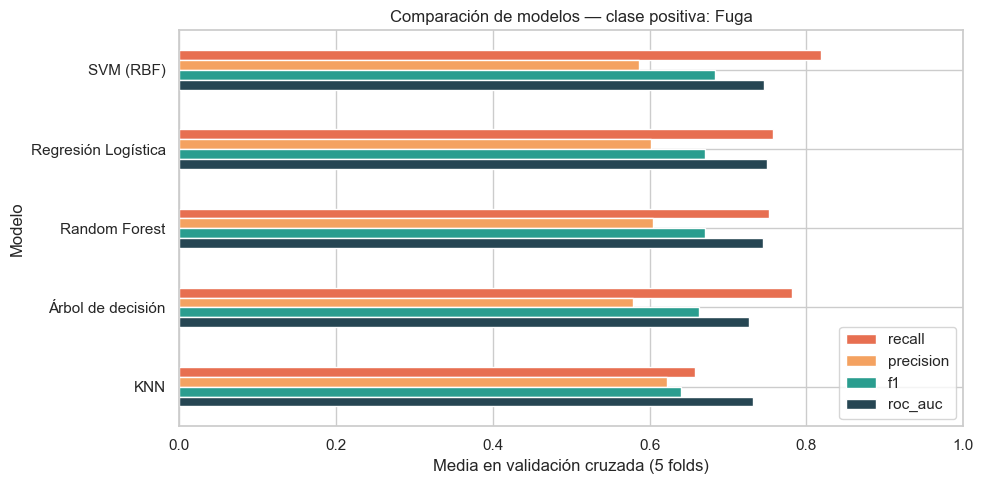

In [155]:
# Comparativa visual (validación cruzada, NO test)
ax = tabla_cv.drop(index='Baseline (siempre "vuelve")')[['recall', 'precision', 'f1', 'roc_auc']].plot(
    kind='barh', figsize=(10, 5), color=['#e76f51', '#f4a261', '#2a9d8f', '#264653'])
ax.set_xlim(0, 1); ax.set_xlabel('Media en validación cruzada (5 folds)')
ax.set_title('Comparación de modelos — clase positiva: Fuga')
ax.invert_yaxis(); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 5.3 ¿Qué aporta el balanceo?
Mismo modelo (Regresión Logística) **con y sin** `class_weight='balanced'`, para ver el efecto sobre el recall de la fuga.

In [156]:
comp_bal = {}
for etiqueta, cw in [('Sin balanceo', None), ('Con class_weight="balanced"', 'balanced')]:
    r = cross_validate(crear_pipeline(LogisticRegression(class_weight=cw, max_iter=1000)),
                       X_train, y_train, cv=cv, scoring=metricas)
    comp_bal[etiqueta] = {m: r[f'test_{m}'].mean() for m in metricas}
pd.DataFrame(comp_bal).T.round(3)

,accuracy,recall,precision,f1,roc_auc
Sin balanceo,0.686,0.659,0.632,0.645,0.75
"Con class_weight=""balanced""",0.677,0.747,0.603,0.668,0.75


## 5.4 Modelo seleccionado
Elegimos el de **mayor F1 medio en validación cruzada**. Ojo: si las diferencias entre modelos son menores que su desviación típica (`f1_std`), el "empate técnico" se comenta en las decisiones.

In [157]:
modelo_elegido = tabla_cv.drop(index='Baseline (siempre "vuelve")').index[0]
mejor_modelo = mejores[modelo_elegido]
print('Modelo elegido por validación cruzada:', modelo_elegido)
print(tabla_cv.loc[modelo_elegido, ['recall', 'precision', 'f1', 'roc_auc', 'f1_std']].astype(float).round(3))

Modelo elegido por validación cruzada: SVM (RBF)
recall       0.819
precision    0.586
f1           0.683
roc_auc      0.745
f1_std       0.011
Name: SVM (RBF), dtype: float64


### 📝 Decisiones F5
- **Baseline:** predice siempre "vuelve" (clase mayoritaria). Su accuracy (~57 %) coincide con el % de clientes que vuelven, pero su **recall de fuga es 0**: no detecta a ningún cliente en riesgo. Para Qelux equivaldría a no lanzar nunca ninguna acción de retención. Por eso la accuracy no sirve como métrica principal.
- **Modelos:** todos superan claramente al baseline. Gana **SVM (RBF)** con F1 = 0,683, pero las diferencias con Random Forest (0,676) y Regresión Logística (0,670) son menores que la variación entre folds (`f1_std` ≈ 0,011–0,014): **empate técnico**. El SVM destaca en **recall (0,819)**: detecta 8 de cada 10 clientes que se van, a costa de algo menos de precisión (0,586).
- **Balanceo (`class_weight='balanced'`):** en la Regresión Logística el recall sube de 0,659 a 0,747 y la precisión baja de 0,632 a 0,603. El modelo se vuelve "más vigilante": detecta más fugas a cambio de enviar algún incentivo de más. Para Qelux compensa, porque un incentivo (p. ej., un inserto de regalo) cuesta mucho menos que perder un cliente.
- **Selección con validación cruzada:** el test se reserva para la evaluación final. La validación cruzada promedia 5 particiones, por lo que depende menos del azar que un único split; usar el test para elegir sería una fuga de información y daría una estimación optimista.

---
# F6. Evaluación final e interpretación
Ahora, y **solo ahora**, usamos el conjunto de **test** (671 clientes que el modelo nunca ha visto) para medir el rendimiento real del modelo elegido en F5.

1. Métricas en test y comparación con la validación cruzada (¿hay sobreajuste?).
2. Matriz de confusión traducida a negocio.
3. Curva ROC.
4. ¿Qué variables usa el modelo? (importancia por permutación).
5. ¿Aporta el **segmento** de F4 como variable? (calculado sin fuga de información).
6. Riesgo de fuga por segmento: del modelo a la acción.

In [158]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, recall_score, precision_score, f1_score, roc_auc_score, accuracy_score)

y_pred = mejor_modelo.predict(X_test)
# Puntuación continua para el ROC-AUC (SVM usa decision_function; otros modelos, predict_proba)
if hasattr(mejor_modelo, 'decision_function'):
    y_score = mejor_modelo.decision_function(X_test)
else:
    y_score = mejor_modelo.predict_proba(X_test)[:, 1]

test_metricas = {'accuracy': accuracy_score(y_test, y_pred), 'recall': recall_score(y_test, y_pred),
                 'precision': precision_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred),
                 'roc_auc': roc_auc_score(y_test, y_score)}
cv_metricas = tabla_cv.loc[modelo_elegido, list(test_metricas)].astype(float)

comparacion = pd.DataFrame({'Validación cruzada (train)': cv_metricas, 'Test': pd.Series(test_metricas)})
comparacion['Diferencia'] = comparacion['Test'] - comparacion['Validación cruzada (train)']
print('Modelo:', modelo_elegido)
comparacion.round(3)

Modelo: SVM (RBF)


,Validación cruzada (train),Test,Diferencia
accuracy,0.670,0.644,-0.026
recall,0.819,0.794,-0.025
precision,0.586,0.563,-0.023
f1,0.683,0.659,-0.024
roc_auc,0.745,0.728,-0.018


In [159]:
print(classification_report(y_test, y_pred, target_names=['Vuelve (0)', 'Fuga (1)'], digits=3))

              precision    recall  f1-score   support

  Vuelve (0)      0.770     0.529     0.627       380
    Fuga (1)      0.563     0.794     0.659       291

    accuracy                          0.644       671
   macro avg      0.667     0.661     0.643       671
weighted avg      0.680     0.644     0.641       671



## 6.1 Matriz de confusión → lenguaje de negocio

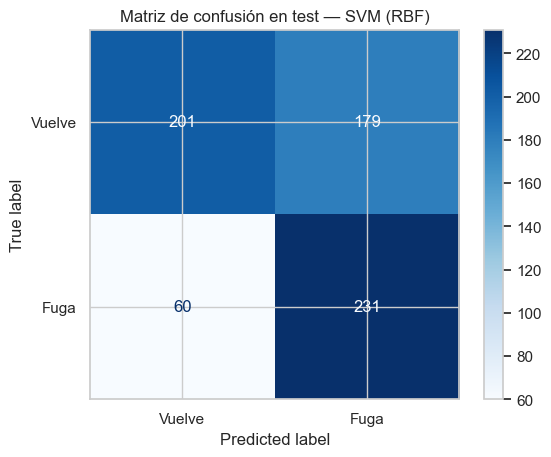

✅ Fugas detectadas a tiempo (VP)            :  231  → recibirían un incentivo y podríamos retenerlas
❌ Fugas NO detectadas (FN, el error caro)   :   60  → se irían sin que hiciéramos nada
💸 Incentivos "de más" (FP)                  :  179  → clientes que habrían vuelto igualmente
👍 Clientes fieles bien identificados (VN)   :  201

De cada 10 clientes que se van, el modelo detecta 7.9.
De cada 10 incentivos enviados, 5.6 llegan a un cliente que realmente estaba en riesgo.


In [160]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Vuelve', 'Fuga']).plot(cmap='Blues', values_format='d')
plt.title(f'Matriz de confusión en test — {modelo_elegido}')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'✅ Fugas detectadas a tiempo (VP)            : {tp:4d}  → recibirían un incentivo y podríamos retenerlas')
print(f'❌ Fugas NO detectadas (FN, el error caro)   : {fn:4d}  → se irían sin que hiciéramos nada')
print(f'💸 Incentivos "de más" (FP)                  : {fp:4d}  → clientes que habrían vuelto igualmente')
print(f'👍 Clientes fieles bien identificados (VN)   : {tn:4d}')
print(f'\nDe cada 10 clientes que se van, el modelo detecta {tp/(tp+fn)*10:.1f}.')
print(f'De cada 10 incentivos enviados, {tp/(tp+fp)*10:.1f} llegan a un cliente que realmente estaba en riesgo.')

## 6.2 Curva ROC
Muestra el equilibrio entre detectar fugas (eje Y) y molestar a clientes fieles (eje X) para **todos** los umbrales posibles. La diagonal es un modelo aleatorio (AUC = 0,5).

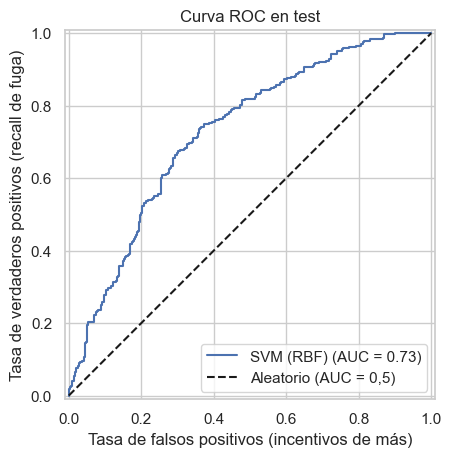

In [161]:
ax = plt.gca()
RocCurveDisplay.from_predictions(y_test, y_score, name=modelo_elegido, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0,5)')
ax.set_xlabel('Tasa de falsos positivos (incentivos de más)')
ax.set_ylabel('Tasa de verdaderos positivos (recall de fuga)')
ax.set_title('Curva ROC en test'); ax.legend(loc='lower right')
plt.show()

## 6.3 ¿Qué variables pesan más? (importancia por permutación)
El SVM no da "importancias" directas. Usamos la **importancia por permutación**: desordenamos al azar una variable en el test y medimos cuánto empeora el **ROC-AUC** (mide si el modelo ordena bien a los clientes por riesgo). Si empeora mucho, el modelo depende de esa variable.

Como contraste, mostramos también la importancia del **Random Forest** (empate técnico con el SVM en F5), que sí la calcula de forma nativa.

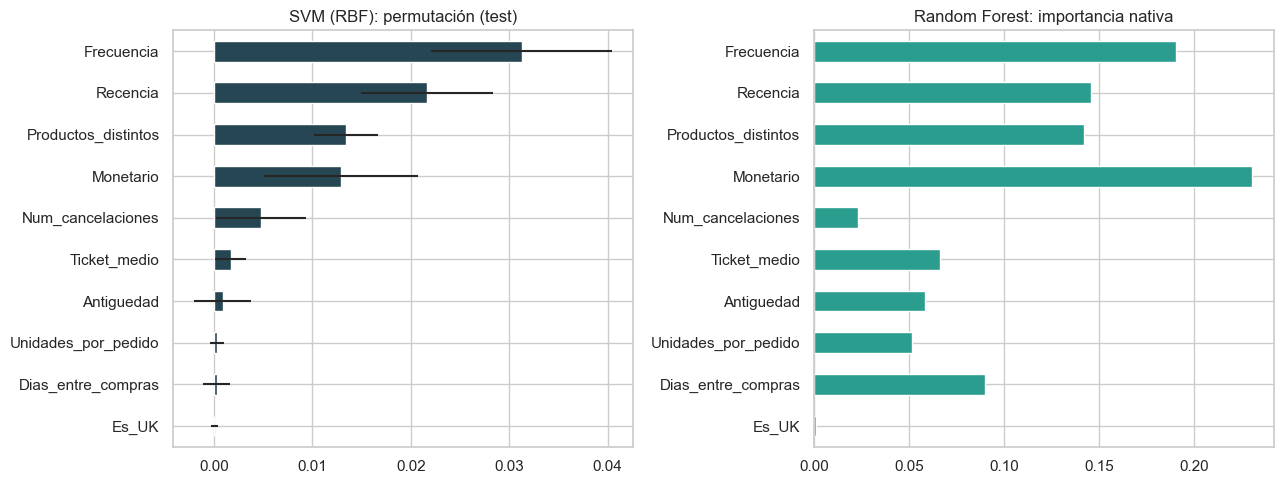

,SVM (RBF) (caída de ROC-AUC),Random Forest (importancia nativa)
Frecuencia,0.031,0.190
Recencia,0.022,0.146
Productos_distintos,0.013,0.142
Monetario,0.013,0.231
Num_cancelaciones,0.005,0.023
Ticket_medio,0.002,0.066
Antiguedad,0.001,0.059
Unidades_por_pedido,0.000,0.052
Dias_entre_compras,0.000,0.090
Es_UK,0.000,0.001


In [162]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(mejor_modelo, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE)
rf_imp = mejores['Random Forest'].named_steps['modelo'].feature_importances_

importancias = pd.DataFrame({f'{modelo_elegido} (caída de ROC-AUC)': imp.importances_mean,
                             'Random Forest (importancia nativa)': rf_imp},
                            index=features).sort_values(f'{modelo_elegido} (caída de ROC-AUC)')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
importancias.iloc[:, 0].plot(kind='barh', xerr=imp.importances_std[np.argsort(imp.importances_mean)],
                             color='#264653', ax=ax[0], title=f'{modelo_elegido}: permutación (test)')
importancias.iloc[:, 1].plot(kind='barh', color='#2a9d8f', ax=ax[1], title='Random Forest: importancia nativa')
plt.tight_layout(); plt.show()
importancias.sort_values(importancias.columns[0], ascending=False).round(3)

## 6.4 ¿Aporta el segmento de F4 como variable?
Para evitar fuga de información, el K-Means se ajusta **dentro del pipeline** (solo con los datos de entrenamiento de cada fold) y añade el segmento como variables 0/1. Comparamos en validación cruzada el mismo modelo **con y sin** segmento.

In [163]:
from sklearn.base import BaseEstimator, TransformerMixin, clone

class AñadirSegmento(BaseEstimator, TransformerMixin):
    """Ajusta K-Means sobre las columnas indicadas (ya transformadas) y añade el segmento como one-hot."""
    def __init__(self, columnas, k=4, random_state=42):
        self.columnas, self.k, self.random_state = columnas, k, random_state
    def fit(self, X, y=None):
        self.km_ = KMeans(n_clusters=self.k, n_init=10, random_state=self.random_state).fit(X[:, self.columnas])
        return self
    def transform(self, X):
        seg = self.km_.predict(X[:, self.columnas])
        return np.hstack([X, np.eye(self.k)[seg]])

idx_seg = [features.index(v) for v in vars_seg]
params_svm = {k.replace('modelo__', ''): v for k, v in mejor_modelo.get_params().items() if k.startswith('modelo__')}

con_segmento = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler()),
    ('segmento', AñadirSegmento(idx_seg, k=K_FINAL, random_state=RANDOM_STATE)),
    ('modelo', clone(mejor_modelo.named_steps['modelo'])),
])

sin = cross_validate(clone(mejor_modelo), X_train, y_train, cv=cv, scoring=metricas)
con = cross_validate(con_segmento, X_train, y_train, cv=cv, scoring=metricas)
pd.DataFrame({'Sin segmento': {m: sin[f'test_{m}'].mean() for m in metricas},
              'Con segmento': {m: con[f'test_{m}'].mean() for m in metricas}}).T.round(3)

,accuracy,recall,precision,f1,roc_auc
Sin segmento,0.670,0.819,0.586,0.683,0.745
Con segmento,0.665,0.830,0.580,0.683,0.745


## 6.5 Del modelo a la acción: riesgo de fuga por segmento (clientes de test)

In [164]:
resultado_test = X_test.copy()
resultado_test['Segmento'] = clientes.loc[X_test.index, 'Segmento']
resultado_test['Fuga_real'] = y_test
resultado_test['Riesgo_predicho'] = y_pred

accion = resultado_test.groupby('Segmento').agg(
    Clientes=('Riesgo_predicho', 'size'),
    En_riesgo_segun_modelo=('Riesgo_predicho', 'sum'),
    Fuga_real=('Fuga_real', 'sum'),
).loc[orden]
accion['% marcados en riesgo'] = (accion['En_riesgo_segun_modelo'] / accion['Clientes'] * 100).round(1)
accion['Acción Qelux'] = ['Acceso anticipado', 'Envío gratis en pedidos grandes',
                          'Puntos de fidelidad', 'Inserto de regalo']
accion

,Clientes,En_riesgo_segun_modelo,Fuga_real,% marcados en riesgo,Acción Qelux
Segmento,,,,,
VIP fieles,141,1,26,0.7,Acceso anticipado
Mayoristas / ticket alto,126,50,42,39.7,Envío gratis en pedidos grandes
Ocasionales,267,226,137,84.6,Puntos de fidelidad
Dormidos de bajo valor,137,133,86,97.1,Inserto de regalo


## 6.6 Alerta VIP: un umbral específico para los mejores clientes
**Problema detectado en 6.5:** el modelo apenas marca a ningún VIP en riesgo, aunque ~18 % de los VIP de test se fugan. Son los clientes más valiosos, así que cada fuga no detectada es la más cara.

**Diagnóstico (solo con train):**
- Un VIP que se va **no parece en riesgo** el día de corte: compró hace poco (recencia baja), igual que los VIP que se quedan. Con un **único umbral global**, sus puntuaciones de riesgo nunca lo superan.
- Pero el modelo **sí sabe ordenarlos**: dentro de los VIP, los que se van tienen puntuaciones más altas que los que se quedan (ver ROC-AUC dentro del segmento).

**Solución:** en lugar del umbral global, para los VIP marcamos como "en alerta" al **20 % con mayor puntuación de riesgo dentro de su segmento**. El umbral se fija **solo con datos de train** (puntuaciones de validación cruzada) y después se comprueba una vez en test.

In [165]:
from sklearn.model_selection import cross_val_predict

PCT_ALERTA_VIP = 0.20
es_vip_train = (clientes.loc[X_train.index, 'Segmento'] == 'VIP fieles').values
es_vip_test  = (clientes.loc[X_test.index,  'Segmento'] == 'VIP fieles').values

# 1) Puntuaciones de riesgo "honestas" en train (cada cliente puntuado por un modelo que no lo vio)
metodo = 'decision_function' if hasattr(mejor_modelo, 'decision_function') else 'predict_proba'
score_train = cross_val_predict(clone(mejor_modelo), X_train, y_train, cv=cv, method=metodo)
score_train = score_train if score_train.ndim == 1 else score_train[:, 1]

print(f'ROC-AUC dentro de los VIP (train, CV): {roc_auc_score(y_train[es_vip_train], score_train[es_vip_train]):.3f}'
      '  → el modelo SÍ ordena a los VIP por riesgo')

# 2) Umbral VIP fijado SOLO con train: percentil 80 de las puntuaciones de los VIP
umbral_vip = np.quantile(score_train[es_vip_train], 1 - PCT_ALERTA_VIP)

# 3) Aplicación en test (una sola vez)
alerta_test = y_pred.copy()
alerta_test[es_vip_test] = (y_score[es_vip_test] >= umbral_vip).astype(int)

def resumen_vip(pred):
    y_v = y_test.values[es_vip_test]; p_v = pred[es_vip_test]
    return {'VIP en test': len(y_v), 'Fugas VIP reales': int(y_v.sum()), 'VIP marcados': int(p_v.sum()),
            'Fugas VIP detectadas': int((p_v & y_v).sum()),
            'Recall VIP': round((p_v & y_v).sum() / y_v.sum(), 3)}

pd.DataFrame({'Umbral global': resumen_vip(y_pred), 'Alerta VIP (top 20 %)': resumen_vip(alerta_test)}).T

ROC-AUC dentro de los VIP (train, CV): 0.759  → el modelo SÍ ordena a los VIP por riesgo


,VIP en test,Fugas VIP reales,VIP marcados,Fugas VIP detectadas,Recall VIP
Umbral global,141.0,26.0,1.0,0.0,0.000
Alerta VIP (top 20 %),141.0,26.0,30.0,11.0,0.423


In [166]:
# Impacto en el resultado global del modelo
pd.DataFrame({
    'Umbral global':         {'recall': recall_score(y_test, y_pred),      'precision': precision_score(y_test, y_pred),      'f1': f1_score(y_test, y_pred)},
    'Con alerta VIP':        {'recall': recall_score(y_test, alerta_test), 'precision': precision_score(y_test, alerta_test), 'f1': f1_score(y_test, alerta_test)},
}).T.round(3)

,recall,precision,f1
Umbral global,0.794,0.563,0.659
Con alerta VIP,0.832,0.551,0.663


> ⚠️ **Nota de rigor:** el problema de los VIP se descubrió al mirar el test en 6.5. Para no "hacer trampa", el umbral VIP se decidió **solo con train** (validación cruzada) y el test se usa una única vez para comprobarlo. Aun así, al haber mirado el test antes, esta mejora debe confirmarse con datos nuevos de Qelux.

**Para Qelux:** la alerta VIP no es un descuento. Es una **llamada o mensaje personal** ("te echamos de menos, ¿qué tal le va a tu perro con el comedero?") y un **acceso anticipado** a la próxima novedad. Barato y coherente con una marca premium.

### 📝 Decisiones F6
- **Generalización:** en test el SVM obtiene F1 = 0,659, recall = 0,794 y ROC-AUC = 0,728, frente a 0,683 / 0,819 / 0,745 en validación cruzada. La caída es pequeña (~2–3 puntos): **no hay sobreajuste relevante** y el modelo generaliza a clientes que nunca vio.
- **Matriz de confusión en lenguaje de negocio:** de cada 10 clientes que se van, el modelo detecta **8** (231 de 291). De cada 10 incentivos enviados, **5,6** llegan a un cliente realmente en riesgo; el resto (179) son "incentivos de más", un coste asumible frente a perder clientes (60 fugas no detectadas).
- **Variables clave:** Frecuencia y Recencia son las que más pesan en el SVM, seguidas de Productos distintos y Monetario; el Random Forest coincide (Monetario y Frecuencia arriba). Encaja con la tabla de medianas de F3: los clientes que se van compran menos veces, hace más tiempo y exploran menos catálogo.
- **Segmento como variable:** no mejora el modelo (F1 igual en validación cruzada). Es lógico: el segmento se construyó con las mismas variables RFM que el modelo ya usa, así que no aporta información nueva. Sigue siendo muy útil para el **negocio**: traduce el riesgo en acciones por tipo de cliente.
- **Hallazgo crítico — los VIP:** con el umbral global el modelo detectaba **0 de 26** fugas VIP. Los VIP que se van no lo parecen el día de corte (compraron hace poco), pero el modelo sí los ordena por riesgo (ROC-AUC = 0,76 dentro del segmento). Con una **alerta VIP** (top 20 % de riesgo dentro del segmento, umbral fijado solo con train) se detectan **11 de 26**, y el recall global sube de 0,794 a 0,832. Debe confirmarse con datos nuevos, ya que el problema se detectó mirando el test.
- **Presupuesto de retención:** Ocasionales y Dormidos concentran la mayoría de clientes marcados (acciones baratas y automatizadas: puntos e inserto de regalo); los VIP en alerta reciben atención personal y acceso anticipado, porque cada fuga VIP es la más cara.

---
# F7. Conclusiones y recomendaciones para Qelux

> **Modelamos cómo compran los clientes, no qué compran.**
> **Usamos un e-commerce de referencia como proxy.**

## 7.1 Resumen ejecutivo
- Partimos de **541.909 transacciones** de un e-commerce de referencia y, tras una limpieza documentada (sin cliente, cancelaciones, compras anuladas, códigos no producto y duplicados), trabajamos con **388.098 líneas de 4.322 clientes** (71,6 % del original).
- El negocio está muy concentrado: **el 1 % de los clientes genera el 30 % del gasto** (patrón de Pareto). Perder a pocos clientes clave cuesta mucho.
- Con una **fecha de corte** (9-sep-2011) construimos un dataset sin fuga temporal: **3.355 clientes**, 10 variables de comportamiento y un target de **fuga a 90 días** (43 % de fuga).
- **No supervisado:** K-Means (K = 4) identifica cuatro perfiles accionables cuya tasa de fuga va del **13 % al 65 %**, sin haber usado la fuga para crearlos.
- **Supervisado:** el mejor modelo (SVM con balanceo de clases) detecta **8 de cada 10 clientes que se van** en datos nunca vistos (recall 0,79; F1 0,66; ROC-AUC 0,73), muy por encima del baseline (recall 0).
- **Hallazgo crítico:** con un umbral único el modelo no detectaba **ninguna** fuga VIP. Una **alerta VIP** con umbral propio (fijado solo con train) detecta **11 de 26**.

## 7.2 Respuesta a las preguntas de negocio
| Pregunta | Respuesta |
|---|---|
| ¿Qué tipos de clientes existen? | **VIP fieles** (21,6 %, fuga 13,4 %), **Mayoristas / ticket alto** (18,7 %, fuga 36,7 %), **Ocasionales** (40,6 %, fuga 52,2 %) y **Dormidos de bajo valor** (19,0 %, fuga 65,2 %). |
| ¿Qué clientes no volverán en 3 meses? | El modelo ordena a cada cliente por riesgo de fuga. Las señales clave son **pocas compras, mucho tiempo desde la última compra y poca variedad de catálogo**. |

## 7.3 Plan de acción para el relanzamiento de Qelux
El comedero antivoracidad es el **producto de entrada**: el objetivo es convertir a quien lo compra en cliente de catálogo. Sin descuentos agresivos, para proteger el posicionamiento premium.

| Segmento | Situación | Acción de fidelización |
|---|---|---|
| VIP fieles | Pocos se van, pero cada fuga es la más cara | **Alerta VIP** + contacto personal + **acceso anticipado** a lanzamientos |
| Mayoristas / ticket alto | Compras grandes y espaciadas (futuras tiendas físicas) | **Envío gratis** en pedidos grandes; seguimiento comercial B2B |
| Ocasionales | Grupo más grande, "moneda al aire" | **Puntos de fidelidad** para convertirlos en recurrentes |
| Dormidos de bajo valor | Compraron una vez, alto riesgo | **Inserto antivoracidad de regalo** en la próxima compra, comunicación automatizada |

## 7.4 Limitaciones
- **Datos proxy:** comercio británico de regalos (2010-2011). Se transfiere la **metodología**, no los números: umbrales y segmentos deben recalibrarse con datos de Qelux.
- **Ventana de 90 días:** puede etiquetar como "fuga" a mayoristas con ciclos de reposición más largos.
- **Una sola fecha de corte:** el modelo se valida en un único momento del año (incluye la temporada navideña en la ventana futura).
- **Alerta VIP:** el problema se detectó mirando el test; aunque el umbral se fijó solo con train, la mejora debe confirmarse con datos nuevos.
- **Predecir la fuga no es lo mismo que evitarla:** el modelo dice *quién* está en riesgo, no *qué incentivo funciona*.
- Se excluyeron las compras sin cliente identificado (~25 %), posiblemente compras como invitado con otro comportamiento.

## 7.5 Próximos pasos
1. **Recoger datos propios** desde el día 1 del e-commerce de Qelux (pedido, cliente, producto, fecha, importe) con el mismo formato.
2. **Reentrenar** el pipeline con esos datos y validar con **varias fechas de corte** (validación temporal).
3. **Test A/B de incentivos** (grupo con incentivo vs grupo control) para medir qué acción retiene realmente a cada segmento.
4. Ajustar el **umbral de decisión según el coste** real de cada incentivo y el valor de cada cliente.
5. Probar modelos de *boosting* y una ventana de fuga específica para clientes B2B.


In [167]:
# Reproducibilidad: versiones utilizadas
import sys, sklearn, matplotlib
print('Python      :', sys.version.split()[0])
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('matplotlib  :', matplotlib.__version__)
print('seaborn     :', sns.__version__)
print('RANDOM_STATE:', RANDOM_STATE)

Python      : 3.9.6
pandas      : 2.3.3
numpy       : 2.0.2
scikit-learn: 1.6.1
matplotlib  : 3.9.4
seaborn     : 0.13.2
RANDOM_STATE: 42
